# Bernoulli Naive Bayes

A pixel block is either active or inactive after thresholding. Bernoulli naive Bayes uses both evidence types when it predicts a digit.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Ten classes

The features use the original block-count scale of 0 to 16. Each method sees the same stratified image split.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import BernoulliNB
from gallery.vision import digits_split, class_scores, confusion

## Score class probabilities

Macro scores give equal weight to all ten digits. Cross-entropy and multiclass Brier loss also check the probabilities assigned to each outcome.

Accuracy 0.873 | Balanced accuracy 0.873 | MCC 0.859
              precision    recall  f1-score   support

           0      0.957     1.000     0.978        45
           1      0.756     0.739     0.747        46
           2      0.923     0.818     0.867        44
           3      0.872     0.891     0.882        46
           4      0.933     0.933     0.933        45
           5      0.932     0.891     0.911        46
           6      0.977     0.956     0.966        45
           7      0.854     0.911     0.882        45
           8      0.723     0.791     0.756        43
           9      0.818     0.800     0.809        45

    accuracy                          0.873       450
   macro avg      0.875     0.873     0.873       450
weighted avg      0.875     0.873     0.874       450

Log loss 0.610 | Macro ROC AUC (one-vs-rest) 0.988
Macro average precision 0.931 | Multiclass Brier 0.206
Training-prior baseline accuracy 0.102, log loss 2.302


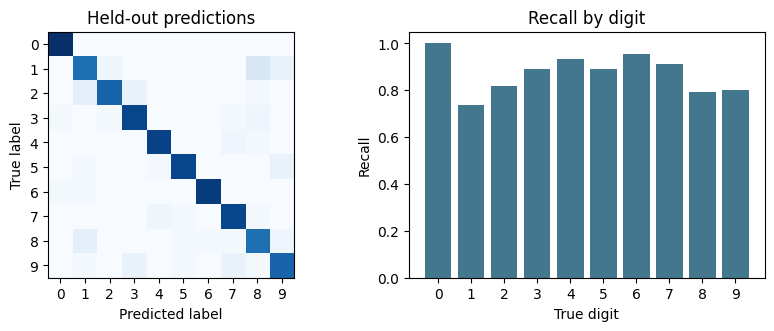

In [3]:
train, test, y, y_test = digits_split()
X = train.reshape(len(train), -1) * 16
T = test.reshape(len(test), -1) * 16
model = BernoulliNB(alpha=1.0, binarize=4.0)
model.fit(X, y)
prob = model.predict_proba(T)
pred = prob.argmax(1)
class_scores(y_test, pred, prob)
prior = np.bincount(y) / len(y)
print(
    f"Training-prior baseline accuracy {(y_test==prior.argmax()).mean():.3f}, log loss {-np.log(prior[y_test]).mean():.3f}"
)
fig, (a, b) = plt.subplots(1, 2, figsize=(7.8, 3.2), constrained_layout=True)
confusion(a, y_test, pred)
by_class = [np.mean(pred[y_test == d] == d) for d in range(10)]
b.bar(np.arange(10), by_class, color="#42778e")
b.set(
    xticks=range(10), ylim=(0, 1.05), title="Recall by digit", xlabel="True digit", ylabel="Recall"
)
plt.show()

## Reading the result

Each recall bar is the fraction of that digit recognised correctly. The confusion matrix identifies the alternative labels assigned to the remainder.

## References

[scikit-learn, BernoulliNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.BernoulliNB.html)

[Alpaydin and Kaynak, Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)